# Visual 3: Who picks the people who set your power rates

**Question.** In which states do voters elect the utility commission, and in which is it appointed?

**Hypothesis.** Most states appoint. Only a small group lets voters choose.

**Sources.** Ballotpedia (May 2026) and Canary Media count 10 states with elected commissions. In South Carolina and Virginia the legislature chooses the commission, so those count as appointed here. Texas voters elect a Railroad Commission, but that body does not set electric rates, so Texas counts as appointed. In Washington, D.C., the mayor appoints the commission.

In [1]:
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image

ELECTED = ["AL", "AZ", "GA", "LA", "MS", "MT", "NE", "ND", "OK", "SD"]

ALL_STATES = [
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
]

TAGS = pd.DataFrame([
    {"state": "VT", "state_lon": -72.7, "state_lat": 44.0, "tag_lon": -75.6, "tag_lat": 46.6},
    {"state": "NH", "state_lon": -71.6, "state_lat": 43.7, "tag_lon": -73.0, "tag_lat": 47.3},
    {"state": "MA", "state_lon": -71.8, "state_lat": 42.3, "tag_lon": -66.9, "tag_lat": 43.3},
    {"state": "RI", "state_lon": -71.5, "state_lat": 41.7, "tag_lon": -67.0, "tag_lat": 41.7},
    {"state": "CT", "state_lon": -72.7, "state_lat": 41.6, "tag_lon": -67.6, "tag_lat": 40.1},
    {"state": "NJ", "state_lon": -74.4, "state_lat": 40.1, "tag_lon": -68.7, "tag_lat": 38.5},
    {"state": "DE", "state_lon": -75.5, "state_lat": 39.0, "tag_lon": -70.0, "tag_lat": 37.0},
    {"state": "MD", "state_lon": -76.8, "state_lat": 39.3, "tag_lon": -71.4, "tag_lat": 35.5},
    {"state": "DC", "state_lon": -77.0, "state_lat": 38.9, "tag_lon": -72.8, "tag_lat": 34.0},
])

## 1. Build the table

In [2]:
states = pd.DataFrame({"state": ALL_STATES})
states["elected"] = states["state"].isin(ELECTED)
states["value"] = states["elected"].astype(int)

elected_count = states["elected"].sum()
appointed_count = len(states) - elected_count

print("Elected:", elected_count)
print("Appointed:", appointed_count)

Elected: 10
Appointed: 40


## 2. The map

Two colors. Blue states elect their commission. Gray states appoint it. States too small for a label get a tag in the margin with a line pointing to the state.

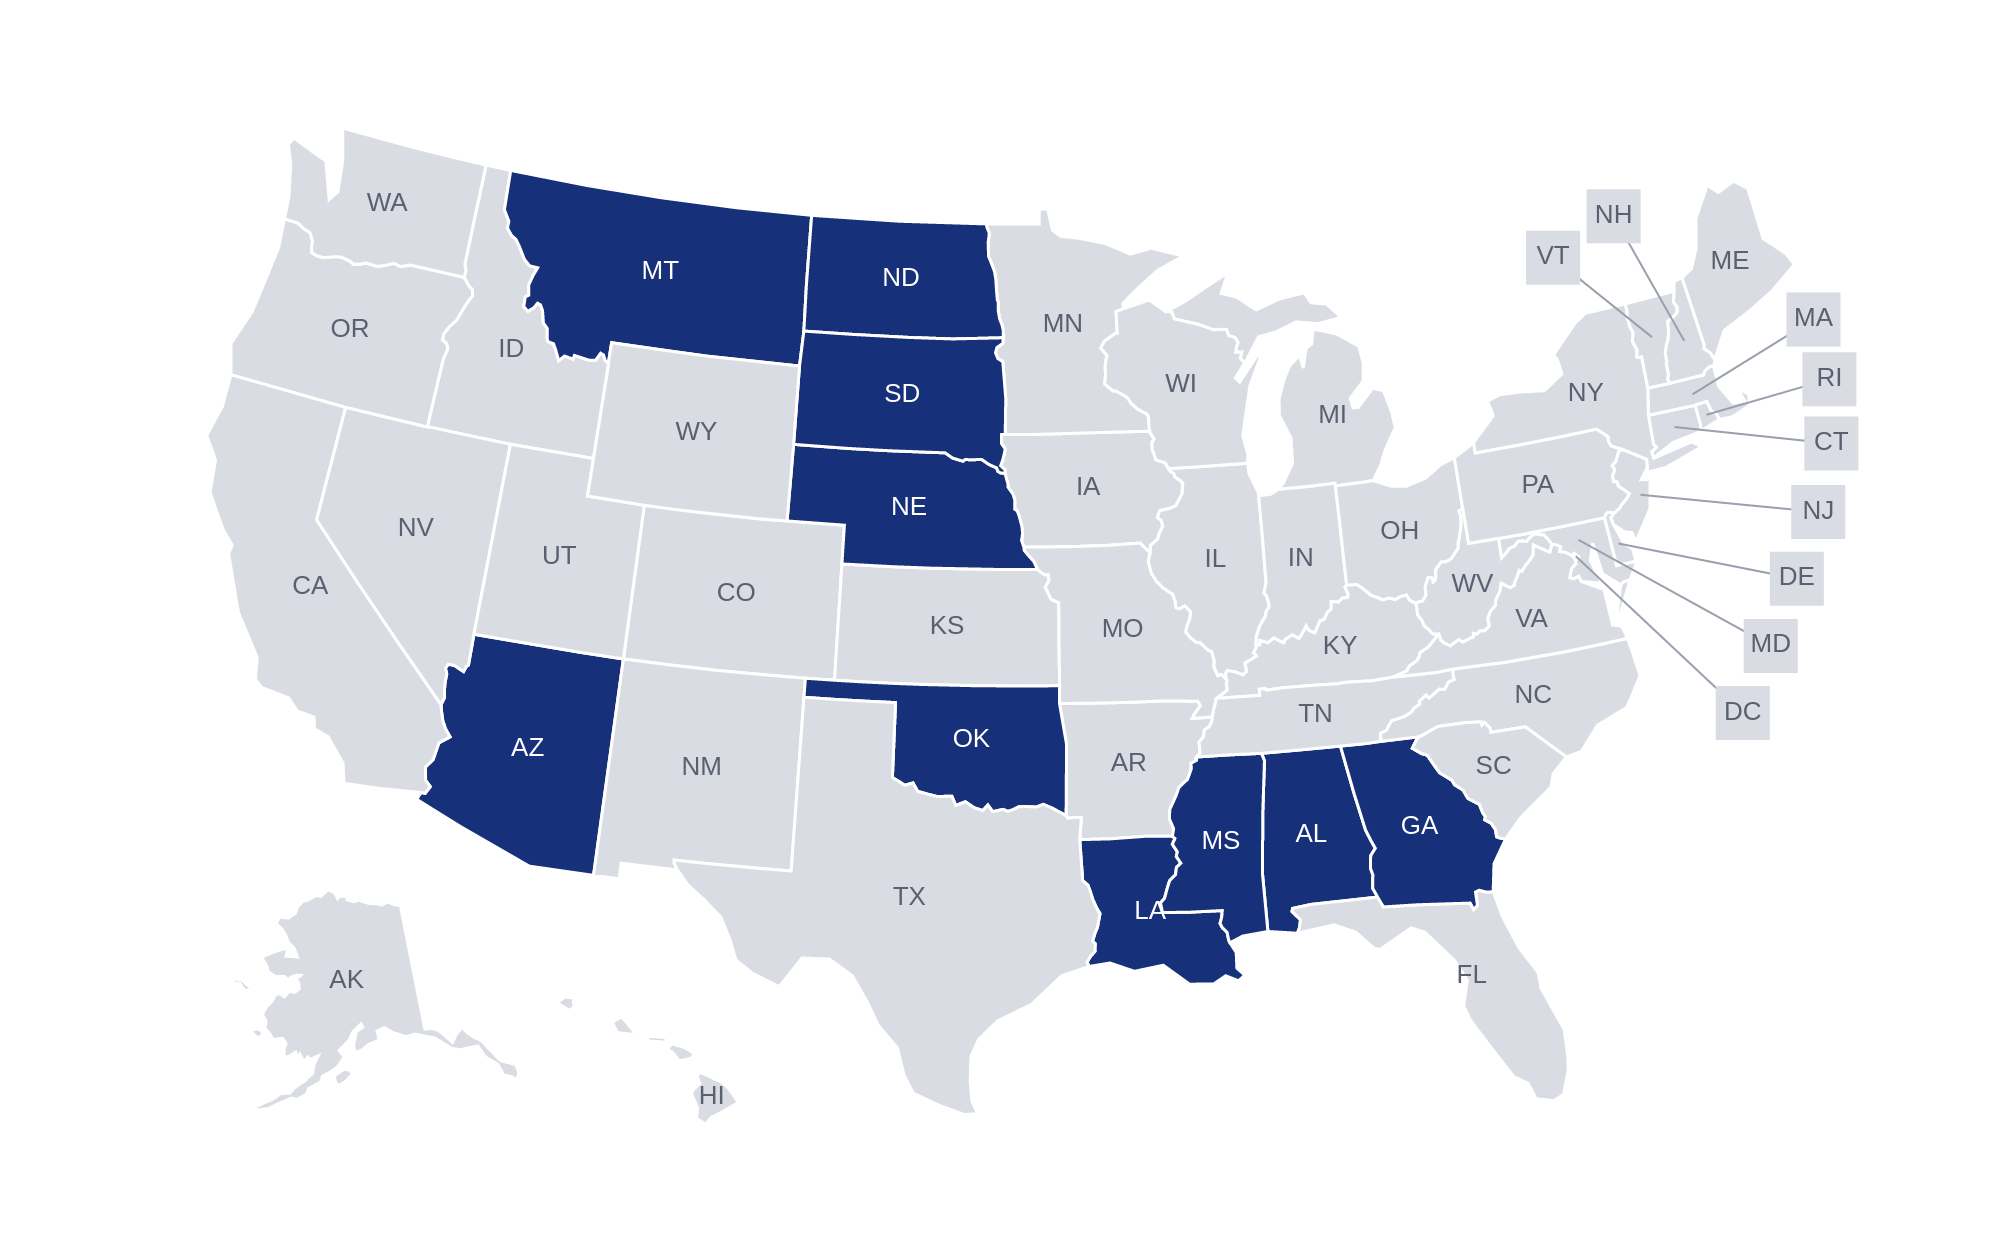

In [3]:
ELECTED_COLOR = "#16307a"
APPOINTED_COLOR = "#d9dce3"
TEXT_COLOR = "#5a6070"
LINE_COLOR = "#9aa0ad"

map_states = list(states["state"]) + ["DC"]
map_values = list(states["value"]) + [0]

labeled = states[~states["state"].isin(TAGS["state"])]
dark_labels = labeled[labeled["elected"]]
light_labels = labeled[~labeled["elected"]]

fig = go.Figure()

fig.add_trace(go.Choropleth(
    locations=map_states,
    z=map_values,
    locationmode="USA-states",
    colorscale=[[0, APPOINTED_COLOR], [1, ELECTED_COLOR]],
    zmin=0,
    zmax=1,
    showscale=False,
    marker_line_color="white",
    marker_line_width=1.5,
))

fig.add_trace(go.Scattergeo(
    locations=dark_labels["state"],
    text=dark_labels["state"],
    locationmode="USA-states",
    mode="text",
    textfont={"color": "white", "size": 13},
))

fig.add_trace(go.Scattergeo(
    locations=light_labels["state"],
    text=light_labels["state"],
    locationmode="USA-states",
    mode="text",
    textfont={"color": TEXT_COLOR, "size": 13},
))

for i in range(len(TAGS)):
    tag = TAGS.iloc[i]
    fig.add_trace(go.Scattergeo(
        lon=[tag["state_lon"], tag["tag_lon"]],
        lat=[tag["state_lat"], tag["tag_lat"]],
        mode="lines",
        line={"color": LINE_COLOR, "width": 1},
    ))

fig.add_trace(go.Scattergeo(
    lon=TAGS["tag_lon"],
    lat=TAGS["tag_lat"],
    text=TAGS["state"],
    mode="markers+text",
    marker={"symbol": "square", "size": 27, "color": APPOINTED_COLOR},
    textfont={"color": TEXT_COLOR, "size": 13},
    textposition="middle center",
))

fig.update_layout(
    geo={"scope": "usa", "bgcolor": "rgba(0,0,0,0)", "showlakes": False, "showland": False},
    paper_bgcolor="rgba(0,0,0,0)",
    margin={"l": 0, "r": 0, "t": 0, "b": 0},
    showlegend=False,
    width=1000,
    height=620,
)

fig.write_image("visual3_who_decides.png", scale=2)
fig.write_image("visual3_who_decides.svg")
fig.write_html("visual3_who_decides.html", include_plotlyjs="cdn")

Image("visual3_who_decides.png", width=800)

## What the map leaves out

- **How appointments work.** In most appointing states the governor picks and the state senate confirms, but the details differ.
- **How elections work.** Some states elect by district and some statewide.
- **Whether it matters.** The map shows who chooses. It does not show whether elected commissions set lower or higher rates.